# F5 · Cross-platform search (Fig 5)

**Run first:** `experiments/compute/R5_cross_platform.ipynb` (writes `results/cross_platform/`).

Panels (each saved to `figures/fig5_cross_platform/panels/`, then the full figure):
* **A** the two sections, cells / spots coloured by coarse class, with tile boxes. The example query is outlined in magenta (Visium) and its top 5 in black (Xenium).
* **B** platform bias: PCA of the shrunk whole-matrix logs, fit on the Xenium tiles; Visium tiles before and after the global shift.
* **C** tissue agreement (seed 0, Spindle-naive with the global shift): query tumour fraction vs its top 10's mean, both directions.
* **D** correction ablation: tissue agreement r per correction and direction (mean ± s.d. over seeds 0–4). In the full figure, the direction legend appears once, under C.
* **E** the example: the Visium query tile and its top 5 Xenium tiles, with focal-class shares.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import style as ps

FIG = "fig5_cross_platform"
RES = ps.ROOT / "results" / "cross_platform"
CLASS_COLORS = {"Invasive tumour": "#CC6677", "DCIS": "#882255", "Myoepithelial": "#DDCC77", "Stroma": "#44AA99",
                "Immune": "#332288", "Adipocytes": "#E69F00", "Mixed": "#AAAAAA"}
PLATFORM = {"Xenium": "#0077BB", "Visium": "#EE7733"}
DIRECTION = {"x2v": PLATFORM["Xenium"], "v2x": PLATFORM["Visium"]}  # coloured by the query platform
DIRECTION_LABEL = {"x2v": "Xenium → Visium", "v2x": "Visium → Xenium"}
SPOT_UM = 55.0

cells = np.load(RES / "cells.npz")
classes = list(cells["classes"])
tiles = pd.read_csv(RES / "tiles.csv")
example = pd.read_csv(RES / "example.csv")
VIS = tiles[tiles.platform == "Visium"].set_index("tile")
XEN = tiles[tiles.platform == "Xenium"].set_index("tile")
X0, Y0 = tiles[["x0", "y0"]].min()
X1, Y1 = tiles[["x1", "y1"]].max()

MAP_W, MAP_GAP, MAP_TOP = 42.0, 2.0, 5.0
MAP_H = MAP_W * (Y1 - Y0) / (X1 - X0)
W_A, H_A = 2 * MAP_W + MAP_GAP, MAP_TOP + MAP_H + 9.0
W_B, H_B = 88.0, H_A
W_CD, H_CD = 52.0, 61.0
W_E, H_E = 74.0, 61.0
print(f"map {MAP_W:.0f} x {MAP_H:.1f} mm")


def points(platform, sel=None):
    xy, cl = cells[f"{platform}_xy"], cells[f"{platform}_class"]
    if sel is not None:
        xy, cl = xy[sel], cl[sel]
    return xy, np.array([CLASS_COLORS[classes[c]] for c in cl])


def spot_size(w_mm, w_um):
    """Marker area (pt^2) of a SPOT_UM-wide spot on an axes w_mm wide showing w_um."""
    return (SPOT_UM / w_um * w_mm / 25.4 * 72) ** 2


def box(ax, r, color, ls="-", lw=0.75):
    ax.add_patch(Rectangle((r.x0, r.y0), r.x1 - r.x0, r.y1 - r.y0, fill=False, ec=color, lw=lw, ls=ls, zorder=5))


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")

map 42 x 57.2 mm


## A · the two sections

figures/fig5_cross_platform/panels/A.pdf/.png: 86 x 71 mm, 1.3 / 1.4 MB


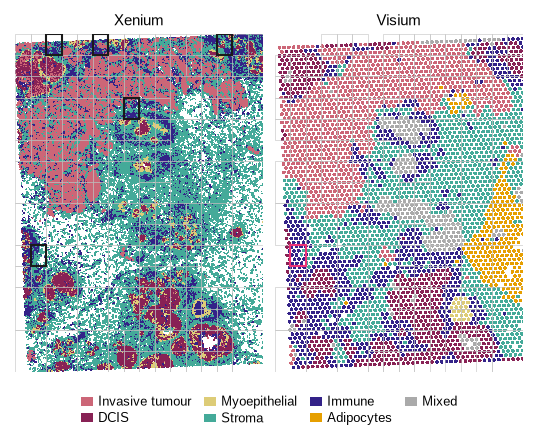

In [2]:
def panel_a(fig):
    for j, platform in enumerate(("Xenium", "Visium")):
        left = j * (MAP_W + MAP_GAP)
        ax = ps.axes(fig, left=left, right=W_A - left - MAP_W, top=MAP_TOP, bottom=H_A - MAP_TOP - MAP_H)
        xy, col = points(platform)
        s = 0.1 if platform == "Xenium" else spot_size(MAP_W, X1 - X0)
        ax.scatter(xy[:, 0], xy[:, 1], s=s, c=col, lw=0, rasterized=True, antialiased=False)
        for r in tiles[tiles.platform == platform].itertuples():
            box(ax, r, "#BDBDBD", lw=0.25)
        if platform == "Visium":
            box(ax, VIS.loc[int(example["query"].iloc[0])], ps.QUERY_COLOR, lw=1.0)
        else:
            for t in example["index_tile"]:
                box(ax, XEN.loc[t], ps.INK, lw=1.0)
        spatial(ax, X0, X1, Y0, Y1)
        ax.text(0.5, 1, platform, transform=ax.transAxes, ha="center", va="bottom", fontsize=ps.LABEL_PT,
                clip_on=False).set_y(1 + 1.0 / MAP_H)
    present = [c for c in classes if c in CLASS_COLORS]
    fig.legend(handles=[Patch(fc=CLASS_COLORS[c], ec="none", label=c) for c in present], loc="lower center",
               bbox_to_anchor=(0.5, 0.0), ncol=4, handlelength=1.0, columnspacing=1.0)


fig = ps.panel(W_A, H_A)
panel_a(fig)
ps.save_panel(fig, FIG, "A")
plt.show()

## B · platform bias (PCA of the whole-matrix logs)

figures/fig5_cross_platform/panels/B.pdf/.png: 88 x 71 mm, 0.0 / 0.4 MB


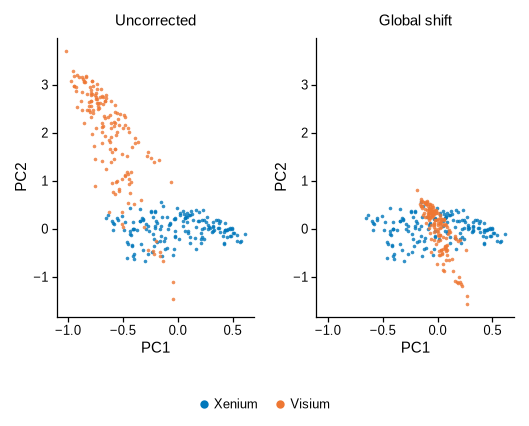

In [3]:
def panel_b(fig):
    p = pd.read_csv(RES / "bias_pca.csv")
    p = p[p.direction == "v2x"]
    idx, qs = p[p.role == "index"], {c: p[(p.role == "query") & (p.corrected == c)] for c in (False, True)}
    allp = pd.concat([idx, *qs.values()])
    pad = 0.05
    lim = [(allp[c].min() - pad * np.ptp(allp[c]), allp[c].max() + pad * np.ptp(allp[c])) for c in ("PC1", "PC2")]
    w = W_B / 2
    for j, (corr, title) in enumerate(((False, "Uncorrected"), (True, "Global shift"))):
        ax = ps.axes(fig, left=j * w + 9.0, right=(1 - j) * w + 1.5, top=MAP_TOP + 3, bottom=16.0)
        ax.scatter(idx.PC1, idx.PC2, s=3, c=PLATFORM["Xenium"], lw=0, alpha=0.8)
        ax.scatter(qs[corr].PC1, qs[corr].PC2, s=3, c=PLATFORM["Visium"], lw=0, alpha=0.8)
        ax.set_xlim(*lim[0])
        ax.set_ylim(*lim[1])
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_title(title, fontsize=ps.LABEL_PT, pad=6)
    fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color=PLATFORM[m], label=m) for m in ("Xenium", "Visium")],
               loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2, handletextpad=0.2)


fig = ps.panel(W_B, H_B)
panel_b(fig)
ps.save_panel(fig, FIG, "B")
plt.show()

## C · tissue agreement (seed 0, global shift)

figures/fig5_cross_platform/panels/C.pdf/.png: 52 x 61 mm, 0.0 / 0.3 MB


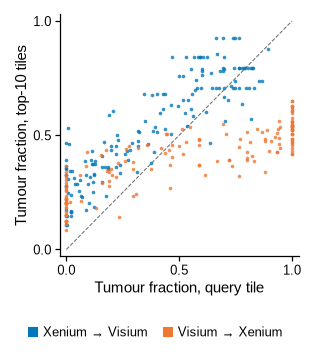

In [4]:
def direction_legend(fig):
    fig.legend(handles=[Line2D([], [], ls="", marker="s", ms=4, color=DIRECTION[d], label=DIRECTION_LABEL[d])
                        for d in ("x2v", "v2x")], loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2,
               handletextpad=0.2, columnspacing=1.0)


def panel_c(fig):
    t = pd.read_csv(RES / "tissue_seed0.csv")
    ax = ps.axes(fig, left=10.0, bottom=14.0, right=1.5, top=6.0)
    ax.plot([0, 1], [0, 1], ls="--", lw=0.5, color=ps.MUTED, zorder=1)
    for d in ("x2v", "v2x"):
        g = t[t.direction == d]
        ax.scatter(g.query_tumour, g.hits_tumour, s=3, c=DIRECTION[d], lw=0, alpha=0.8, zorder=2)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("Tumour fraction, query tile")
    ax.set_ylabel("Tumour fraction, top-10 tiles")
    direction_legend(fig)


fig = ps.panel(W_CD, H_CD)
panel_c(fig)
ps.save_panel(fig, FIG, "C")
plt.show()

## D · correction ablation

figures/fig5_cross_platform/panels/D.pdf/.png: 52 x 61 mm, 0.0 / 0.1 MB


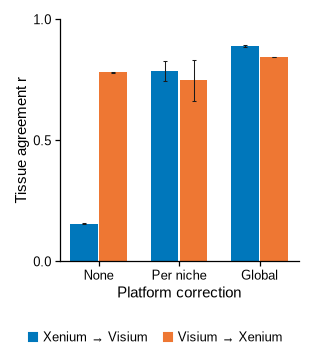

In [5]:
def panel_d(fig, legend=True):
    t = pd.read_csv(RES / "tissue.csv").set_index(["direction", "method"])
    arms = [("naive_none", "None"), ("naive_per_niche", "Per niche"), ("naive_global", "Global")]
    ax = ps.axes(fig, left=10.0, bottom=14.0, right=1.5, top=6.0)
    w = 0.36
    for j, d in enumerate(("x2v", "v2x")):
        x = np.arange(len(arms)) + (j - 0.5) * w
        m = [t.loc[(d, a), "tissue_r_mean"] for a, _ in arms]
        s = [t.loc[(d, a), "tissue_r_std"] for a, _ in arms]
        ax.bar(x, m, w * 0.95, color=DIRECTION[d], lw=0, zorder=2)
        ax.errorbar(x, m, yerr=s, fmt="none", ecolor=ps.INK, elinewidth=0.5, capsize=1.0, capthick=0.5, zorder=3)
    ax.set_xticks(range(len(arms)))
    ax.set_xticklabels([l for _, l in arms])
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("Platform correction")
    ax.set_ylabel("Tissue agreement r")
    if legend:  # the full figure shows it once, under C
        direction_legend(fig)


fig = ps.panel(W_CD, H_CD)
panel_d(fig)
ps.save_panel(fig, FIG, "D")
plt.show()

## E · the example query and its top 5

figures/fig5_cross_platform/panels/E.pdf/.png: 74 x 61 mm, 0.3 / 0.4 MB


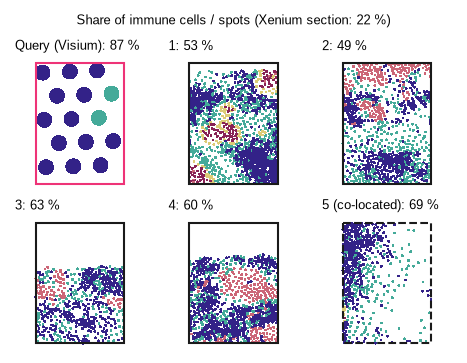

In [6]:
TW, TS, E_TOP = 22.0, 27.0, 8.0  # tile width, row step, header (mm)


def zoom(fig, x, y, platform, r, color, ls, label):
    ax = ps.axes(fig, left=x, right=W_E - x - TW, top=y, bottom=H_E - y - TW)
    side = max(r.x1 - r.x0, r.y1 - r.y0) * 1.08
    cx, cy = (r.x0 + r.x1) / 2, (r.y0 + r.y1) / 2
    xy = cells[f"{platform}_xy"]
    sel = np.flatnonzero((xy[:, 0] >= r.x0) & (xy[:, 0] < r.x1) & (xy[:, 1] >= r.y0) & (xy[:, 1] < r.y1))
    xy, col = points(platform, sel)
    s = 0.8 if platform == "Xenium" else spot_size(TW, side)
    ax.scatter(xy[:, 0], xy[:, 1], s=s, c=col, lw=0, rasterized=True, antialiased=False)
    box(ax, r, color, ls=ls, lw=1.0)
    spatial(ax, cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2)
    ax.text(0, 1 + 1.0 / TW, label, transform=ax.transAxes, ha="left", va="bottom", fontsize=ps.TICK_PT)


def panel_e(fig):
    e = example
    cls = e["focal_class"].iloc[0].lower()
    fig.text(0.5, 1 - 0.5 / H_E, f"Share of {cls} cells / spots (Xenium section: {100 * e['section_share'].iloc[0]:.0f} %)",
             ha="center", va="top", fontsize=ps.TICK_PT)
    gap = (W_E - 3 * TW) / 2
    pos = [(c * (TW + gap), E_TOP + r * TS) for r in range(2) for c in range(3)]
    zoom(fig, *pos[0], "Visium", VIS.loc[int(e["query"].iloc[0])], ps.QUERY_COLOR, "-",
         f"Query (Visium): {100 * e['query_share'].iloc[0]:.0f} %")
    for r in e.itertuples():
        zoom(fig, *pos[r.rank], "Xenium", XEN.loc[r.index_tile], ps.INK, "--" if r.matched else "-",
             f"{r.rank}{' (co-located)' if r.matched else ''}: {100 * r.hit_share:.0f} %")


fig = ps.panel(W_E, H_E)
panel_e(fig)
ps.save_panel(fig, FIG, "E")
plt.show()

## Full figure

figures/fig5_cross_platform/fig5_cross_platform.pdf/.png: 180 x 134 mm, 1.6 / 3.0 MB


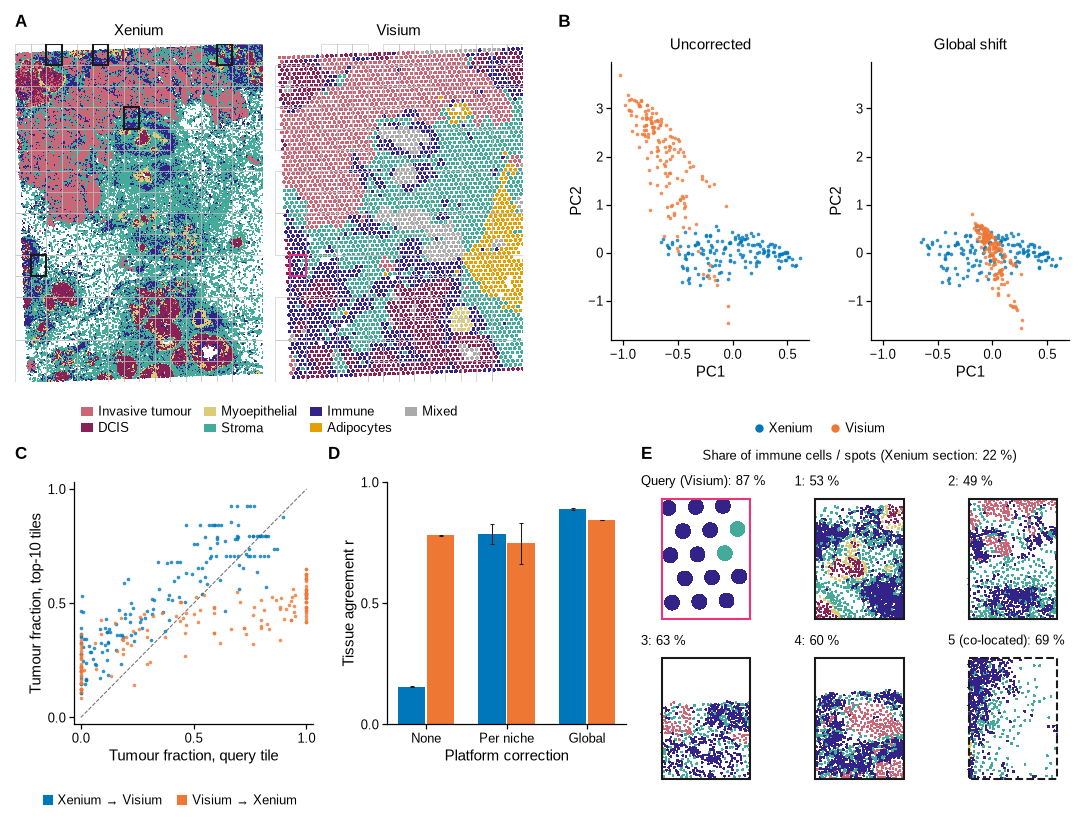

In [7]:
ROW2 = H_A + 2.0
page = ps.page(180, ROW2 + H_CD)
panel_a(ps.place(page, "A", 0, 0, W_A, H_A))
panel_b(ps.place(page, "B", 180 - W_B, 0, W_B, H_B))
panel_c(ps.place(page, "C", 0, ROW2, W_CD, H_CD))
panel_d(ps.place(page, "D", W_CD + 1, ROW2, W_CD, H_CD), legend=False)
panel_e(ps.place(page, "E", 180 - W_E, ROW2, W_E, H_E))
ps.save_figure(page, FIG)
plt.show()